# Comparing the preprocessing approaches

Every approach is evaluated with **the same XGBoost hyperparameters**, so differences in the results come only from the data preparation.
The winner is chosen by the **mean macro-F1 across the CV folds**; the best approach is then tuned in `03_xgboost_tuning.ipynb`.

Macro-F1 is the main metric because it gives every class the same weight — with accuracy, the large class 3 would dominate and
the 64 houses of class 6 would barely count.

## 1. Load the processed datasets

In [1]:
import itertools
import json

import matplotlib.pyplot as plt
import pandas as pd
import xgboost as xgb
from sklearn.metrics import recall_score
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split

from common import (RANDOM_STATE, RESULTS_DIR, compute_scores, cross_validate, fit_model,
                    load_processed, split_features_target)

APPROACHES = {
    "A": "A_baseline",
    "B": "B_native_categorical",
    "C": "C_feature_engineering",
}
datasets = {key: split_features_target(load_processed(name)) for key, name in APPROACHES.items()}

pd.DataFrame({key: {"houses": X.shape[0], "features": X.shape[1],
                    "categorical": (X.dtypes == "category").sum(), "missing values": int(X.isna().sum().sum())}
              for key, (X, y) in datasets.items()}).T

,houses,features,categorical,missing values
A,2930,201,0,497
B,2930,79,44,15749
C,2930,208,0,497


## 2. Evaluation setup

**Fixed model:** XGBoost with its **default hyperparameters** (100 trees, depth 6, learning rate 0.3). Using the defaults means
no approach is favoured by settings chosen for it. `enable_categorical=True` is needed for approach B and has no effect on A and C.

**Grid:** every combination of

| Setting | Values |
|---|---|
| Approach | A, B, C |
| Test size | 10%, 20% |
| Stratification (train/test split and CV folds) | yes, no |
| k-fold CV on the training part | 5, 10 |
| Outlier removal (`Gr Liv Area > 4000`, training data only) | yes, no |

= 48 experiments. For each one:
1. Split into training and test part.
2. k-fold CV on the training part → train and validation scores per fold (mean ± std).
3. Fit on the whole training part → score on the test part.

Outliers are only ever removed from the data a model is *trained* on; validation folds and the test part keep all houses.

In [2]:
def make_model():
    return xgb.XGBClassifier(enable_categorical=True, random_state=RANDOM_STATE, n_jobs=-1)


def run_experiment(approach, test_size, stratified, k, remove_outliers):
    X, y = datasets[approach]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y if stratified else None, random_state=RANDOM_STATE)
    cv_class = StratifiedKFold if stratified else KFold
    cv = cv_class(n_splits=k, shuffle=True, random_state=RANDOM_STATE)

    folds = cross_validate(make_model, X_train, y_train, cv, remove_outliers=remove_outliers)
    model = fit_model(make_model(), X_train, y_train, remove_outliers=remove_outliers)
    test_scores = compute_scores(y_test, model.predict(X_test))

    settings = {"approach": approach, "test_size": test_size, "stratified": stratified,
                "k": k, "remove_outliers": remove_outliers}
    summary = {**settings,
               **folds.drop(columns="fold").mean().add_suffix("_mean"),
               **folds.filter(like="val_").std().add_suffix("_std"),
               **{f"test_{m}": v for m, v in test_scores.items()}}
    return summary, folds.assign(**settings)

The grid takes several minutes, so the results are saved to `results/` and loaded on later runs.
Set `RERUN = True` to compute them again.

In [3]:
RERUN = False
SUMMARY_PATH = RESULTS_DIR / "compare_preprocessing.csv"
FOLDS_PATH = RESULTS_DIR / "compare_preprocessing_folds.csv"

GRID = list(itertools.product(APPROACHES, [0.1, 0.2], [True, False], [5, 10], [False, True]))

if RERUN or not SUMMARY_PATH.exists():
    RESULTS_DIR.mkdir(exist_ok=True)
    summaries, all_folds = [], []
    for i, settings in enumerate(GRID, start=1):
        summary, folds = run_experiment(*settings)
        summaries.append(summary)
        all_folds.append(folds)
        print(f"{i}/{len(GRID)} {settings} -> CV macro-F1 {summary['val_f1_mean']:.3f}")
    results = pd.DataFrame(summaries)
    folds = pd.concat(all_folds, ignore_index=True)
    results.to_csv(SUMMARY_PATH, index=False)
    folds.to_csv(FOLDS_PATH, index=False)
else:
    results = pd.read_csv(SUMMARY_PATH)
    folds = pd.read_csv(FOLDS_PATH)

print(len(results), "experiments")

48 experiments


## 3. Results

### 3.1 CV macro-F1 for every setting
Each cell is the mean CV macro-F1 over the k folds. Read across a row to compare the approaches under identical conditions.

In [4]:
SETTINGS = ["test_size", "stratified", "k", "remove_outliers"]

f1_table = results.pivot_table(index=SETTINGS, columns="approach", values="val_f1_mean")
f1_table["best"] = f1_table.idxmax(axis=1)
f1_table.style.format("{:.3f}", subset=list(APPROACHES)).background_gradient(axis=1, cmap="Greens", subset=list(APPROACHES))

In [5]:
METRICS = ["accuracy", "precision", "recall", "f1"]

overall = results.groupby("approach").agg(
    **{f"CV {m}": (f"val_{m}_mean", "mean") for m in METRICS},
    **{"CV f1 std (across folds)": ("val_f1_std", "mean"),
       "train f1": ("train_f1_mean", "mean"),
       "test f1": ("test_f1", "mean")},
)
overall["settings won"] = f1_table["best"].value_counts().reindex(overall.index, fill_value=0)
overall.round(3)

,CV accuracy,CV precision,CV recall,CV f1,CV f1 std (across folds),train f1,test f1,settings won
approach,,,,,,,,
A,0.750,0.762,0.720,0.734,0.036,0.998,0.741,5
B,0.744,0.757,0.712,0.728,0.033,0.998,0.730,1
C,0.753,0.762,0.731,0.740,0.035,0.998,0.754,10


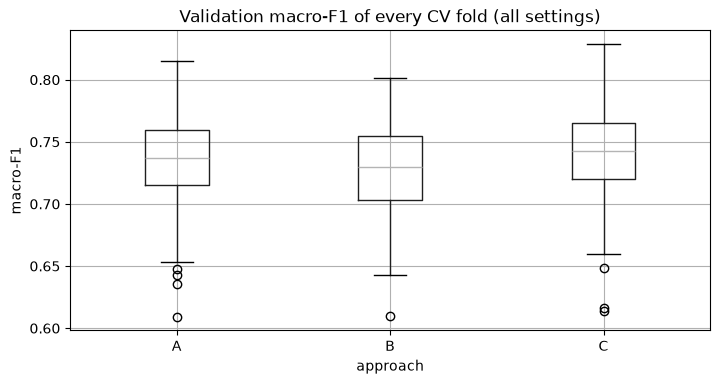

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
folds.boxplot(column="val_f1", by="approach", ax=ax)
ax.set_title("Validation macro-F1 of every CV fold (all settings)"); ax.set_xlabel("approach"); ax.set_ylabel("macro-F1")
fig.suptitle("")
plt.show()

**Interpretation — approaches**
- **C (feature engineering) is the best approach**: highest mean CV macro-F1 (0.740 vs. 0.734 for A and 0.728 for B),
  best in 10 of the 16 settings, and also the highest test score (0.754).
- **A beats B**: the manual cleaning and encoding help a little compared with giving XGBoost the raw data.
- **The differences are small**: about 0.006 macro-F1 between neighbouring approaches, while single folds vary by ≈ 0.035.
  The ranking C > A > B is consistent across settings, which is what makes it convincing — not the size of the gap.
- All three approaches have the same weak spot (see section 4): the default model overfits heavily.

### 3.2 Effect of each evaluation setting
Mean CV macro-F1 for each value of a setting, averaged over everything else.

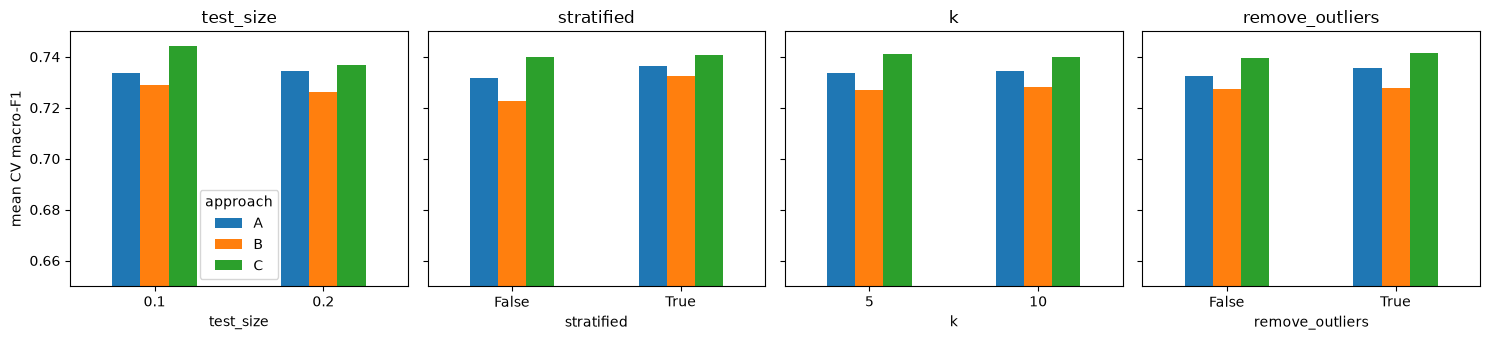

val_f1_mean  val_f1_std
stratified k  remove_outliers                         
False      5  False                 0.7299      0.0264
              True                  0.7355      0.0254
           10 False                 0.7295      0.0489
              True                  0.7307      0.0509
True       5  False                 0.7333      0.0225
              True                  0.7367      0.0278
           10 False                 0.7396      0.0378
              True                  0.7369      0.0364

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5), sharey=True)
for ax, setting in zip(axes, SETTINGS):
    effect = results.pivot_table(index=setting, columns="approach", values="val_f1_mean")
    effect.plot.bar(ax=ax, rot=0, legend=ax is axes[0])
    ax.set_title(setting); ax.set_ylim(0.65, 0.75)
axes[0].set_ylabel("mean CV macro-F1")
fig.tight_layout()
plt.show()

results.groupby(SETTINGS[1:])[["val_f1_mean", "val_f1_std"]].mean().round(4)

**Interpretation — evaluation settings**
- **Stratification** is the clearest effect: higher macro-F1 and less variation between folds (std ≈ 0.030 vs. 0.040).
  Without it, a fold can by chance contain very few houses of class 6 (64 houses in total), which makes its score unstable.
- **k = 5 vs. k = 10**: almost the same mean score (0.734), but the fold scores vary much more with k = 10 (std 0.044 vs. 0.026).
  Each validation fold is half the size (≈ 260 vs. ≈ 530 houses), so a single fold's score is noisier.
  The *mean* of 10 folds is still a good estimate, and each model is trained on more data (90% vs. 80%).
- **Outlier removal** helps slightly for all three approaches (+0.001 to +0.003 CV macro-F1) — a small effect, since only 5 houses are removed.

### 3.3 CV score vs. test score
The test part is a single split, so its score is noisier than the CV mean — especially with a 10% test part (≈ 293 houses,
only ≈ 6 of them in class 6).

In [8]:
results.pivot_table(index=["test_size", "stratified"], columns="approach",
                    values=["val_f1_mean", "test_f1"]).round(3)

test_f1               val_f1_mean              
approach                   A      B      C           A      B      C
test_size stratified                                                
0.1       False        0.728  0.707  0.726       0.730  0.722  0.748
          True         0.743  0.725  0.768       0.737  0.736  0.741
0.2       False        0.737  0.751  0.765       0.733  0.723  0.733
          True         0.757  0.736  0.757       0.736  0.729  0.741

**Interpretation — test score**
- CV and test scores agree within about ±0.02, so the CV results are a reliable guide.
- With a **10% test part**, the test scores vary more between settings (std 0.021 vs. 0.013 with 20%): ≈ 293 houses, only ≈ 6
  of them in class 6, so a few predictions change the macro-F1 noticeably. A **20% test part** gives a more trustworthy final estimate.

## 4. Bias-variance interpretation
- **Training score ≫ validation score** → the model fits the training data much better than new data → **high variance** (overfitting).
- **Both scores low** → the model is too simple → **high bias**.
- **Spread of the validation score across folds** → how much the result depends on which houses happen to be in a fold.

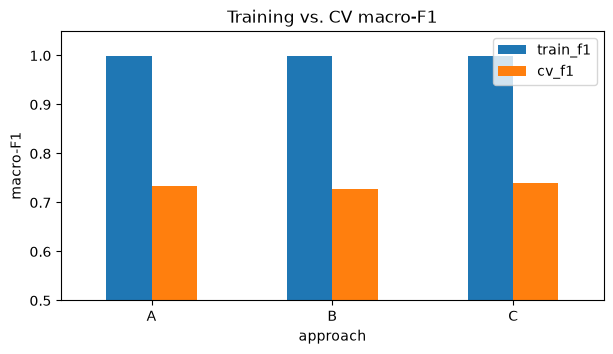

,train_f1,cv_f1,fold_std,gap (train - CV)
approach,,,,
A,0.998,0.734,0.036,0.264
B,0.998,0.728,0.033,0.271
C,0.998,0.740,0.035,0.258


In [9]:
bias_variance = results.groupby("approach").agg(
    train_f1=("train_f1_mean", "mean"), cv_f1=("val_f1_mean", "mean"), fold_std=("val_f1_std", "mean"))
bias_variance["gap (train - CV)"] = bias_variance["train_f1"] - bias_variance["cv_f1"]

ax = bias_variance[["train_f1", "cv_f1"]].plot.bar(rot=0, figsize=(7, 3.5), ylim=(0.5, 1.05))
ax.set_ylabel("macro-F1"); ax.set_title("Training vs. CV macro-F1")
plt.show()
bias_variance.round(3)

In [10]:
fold_spread = results.groupby(["approach", "k"])["val_f1_std"].mean().unstack()
fold_spread.columns = [f"k = {k}" for k in fold_spread.columns]
fold_spread.round(4)

,k = 5,k = 10
approach,,
A,0.0255,0.0457
B,0.0242,0.0418
C,0.0269,0.0430


**Interpretation — bias-variance**
- The training macro-F1 is **≈ 1.0** for every approach, the CV macro-F1 only **≈ 0.73–0.74**: a gap of ≈ 0.26.
  The default model (100 trees of depth 6, learning rate 0.3) almost memorises the training data → **high variance**, low bias.
- This is the same for all approaches, so it does not change the ranking — but it shows where the tuning in `03` should help:
  shallower trees (`max_depth`), a lower learning rate with more trees, a minimum leaf size (`min_child_weight`),
  row/column subsampling and L1/L2 regularisation all reduce variance.
- The fold-to-fold spread (≈ 0.03) is the second sign of variance: the result depends on which houses happen to be in a fold.

## 5. Imbalanced classes on the best approach
The best approach is now tested with three ways of handling the imbalanced classes (class 6 has 2.2% of the houses):

| Method | How it works |
|---|---|
| none | every house has the same weight |
| class weights | each house is weighted inversely to the size of its class (`sample_weight`), so errors on rare classes cost more |
| SMOTE | creates synthetic houses for the smaller classes by interpolating between a house and its nearest neighbours of the same class, until all classes are equally large |

Both methods are applied **only to the training folds**; validation folds keep the real class distribution.

Settings for this and the next notebook: **20% test part, stratified, k = 10** — stratification is clearly better, a 20% test part
gives a less noisy final estimate, and k = 10 trains each fold's model on more data. Outlier removal is chosen from the grid results.

In [11]:
BEST_APPROACH = overall["CV f1"].idxmax()
EVAL_SETTINGS = {"test_size": 0.2, "stratified": True, "k": 10}
print("Best approach:", BEST_APPROACH, "| evaluation settings:", EVAL_SETTINGS)

X, y = datasets[BEST_APPROACH]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=EVAL_SETTINGS["test_size"], stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=EVAL_SETTINGS["k"], shuffle=True, random_state=RANDOM_STATE)

Best approach: C | evaluation settings: {'test_size': 0.2, 'stratified': True, 'k': 10}


In [12]:
outlier_effect = results[results["approach"] == BEST_APPROACH].groupby("remove_outliers")["val_f1_mean"].mean()
REMOVE_OUTLIERS = bool(outlier_effect.idxmax())
print("Mean CV macro-F1 by outlier removal:", outlier_effect.round(4).to_dict(), "-> remove outliers:", REMOVE_OUTLIERS)

balance_rows = {}
balance_folds = {}
for method in [None, "class_weight", "smote"]:
    name = method or "none"
    fold_scores = cross_validate(make_model, X_train, y_train, cv, remove_outliers=REMOVE_OUTLIERS, balance=method)
    balance_folds[name] = fold_scores
    balance_rows[name] = {**fold_scores.filter(like="val_").mean(), "val_f1_std": fold_scores["val_f1"].std(),
                          "train_f1": fold_scores["train_f1"].mean()}

balance = pd.DataFrame(balance_rows).T
balance.round(4)

Mean CV macro-F1 by outlier removal: {False: 0.7396, True: 0.7414} -> remove outliers: True


,val_accuracy,val_precision,val_recall,val_f1,val_f1_std,train_f1
none,0.7508,0.7695,0.7249,0.7398,0.0412,0.9982
class_weight,0.7517,0.7574,0.7494,0.7489,0.0324,0.9982
smote,0.7479,0.7629,0.7400,0.7475,0.0296,0.9982


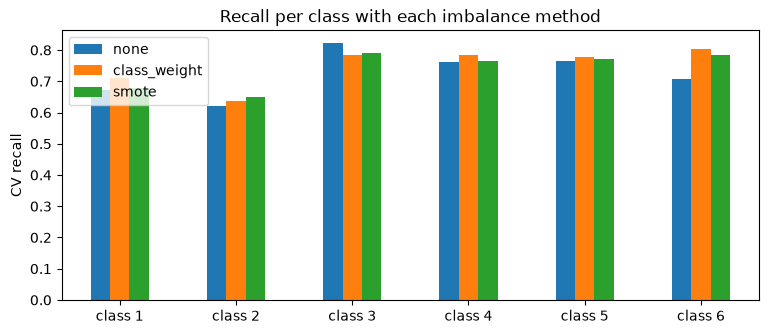

,none,class_weight,smote
class 1,0.672,0.709,0.677
class 2,0.622,0.636,0.651
class 3,0.822,0.784,0.789
class 4,0.763,0.783,0.765
class 5,0.764,0.777,0.770
class 6,0.706,0.804,0.784


In [13]:
per_class_recall = {}
for method in [None, "class_weight", "smote"]:
    preds = pd.Series(index=y_train.index, dtype=int)
    for train_idx, val_idx in cv.split(X_train, y_train):
        model = fit_model(make_model(), X_train.iloc[train_idx], y_train.iloc[train_idx],
                          remove_outliers=REMOVE_OUTLIERS, balance=method)
        preds.iloc[val_idx] = model.predict(X_train.iloc[val_idx])
    per_class_recall[method or "none"] = recall_score(y_train, preds, average=None)

per_class_recall = pd.DataFrame(per_class_recall, index=[f"class {c}" for c in range(1, 7)])
ax = per_class_recall.plot.bar(rot=0, figsize=(9, 3.5))
ax.set_ylabel("CV recall"); ax.set_title("Recall per class with each imbalance method")
plt.show()
per_class_recall.round(3)

**Interpretation — imbalanced classes**
- Both methods improve macro-F1: **class weights 0.749**, SMOTE 0.748, none 0.740.
- The gain comes from the small classes: recall of **class 6 rises from 0.71 to 0.80** with class weights, class 1 from 0.67 to 0.71.
  The price is a lower recall for the large class 3 (0.82 → 0.78): the model now predicts rare classes more often,
  so some class-3 houses are assigned to neighbouring classes. Macro-F1 rewards this trade-off because every class counts equally.
- Class weights and SMOTE are practically equal (difference 0.001, far below the fold spread). **Class weights** are chosen:
  slightly better, simpler, no synthetic houses and no imputation needed, and training stays as fast as before
  (SMOTE doubles the training set to ≈ 5000 houses).

## 6. Conclusion

| Decision | Choice | Evidence |
|---|---|---|
| Preprocessing approach | **C — feature engineering** | highest mean CV macro-F1 (0.740), best in 10/16 settings, highest test score |
| Test size | **20%** | test scores vary less between settings than with 10% |
| Stratification | **yes** | higher macro-F1 and more stable folds |
| k-fold CV | **k = 10** | same mean as k = 5, more training data per fold |
| Outlier removal (training data) | **yes** | small but consistent improvement |
| Imbalanced classes | **class weights** | macro-F1 0.740 → 0.749, class-6 recall 0.71 → 0.80 |

Main issue to address in `03_xgboost_tuning.ipynb`: the default model overfits (training macro-F1 ≈ 1.0 vs. CV ≈ 0.75).

The chosen setup is saved to `results/best_setup.json`, so the tuning notebook uses exactly these settings.

In [14]:
BEST_BALANCE = balance["val_f1"].idxmax()
best_setup = {"approach": BEST_APPROACH, "dataset": APPROACHES[BEST_APPROACH], **EVAL_SETTINGS,
              "remove_outliers": REMOVE_OUTLIERS, "balance": None if BEST_BALANCE == "none" else BEST_BALANCE,
              "baseline_cv_f1": round(balance.loc[BEST_BALANCE, "val_f1"], 4)}
(RESULTS_DIR / "best_setup.json").write_text(json.dumps(best_setup, indent=2))
best_setup

{'approach': 'C',
 'dataset': 'C_feature_engineering',
 'test_size': 0.2,
 'stratified': True,
 'k': 10,
 'remove_outliers': True,
 'balance': 'class_weight',
 'baseline_cv_f1': np.float64(0.7489)}